In [2]:
%pip install ucimlrepo
import pandas as pd
import numpy as np

Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo

# Obtener el conjunto de datos
bank_marketing = fetch_ucirepo(id=222)

print("Dataset obtenido correctamente")

Dataset obtenido correctamente


In [4]:
# Consultar las dimensiones del conjunto de datos
print(bank_marketing.data.features.shape)
print(bank_marketing.data.targets.shape)

(45211, 16)
(45211, 1)


In [5]:
# Consultar los nombres de las variables
print(bank_marketing.variables)

           name     role         type      demographic  \
0           age  Feature      Integer              Age   
1           job  Feature  Categorical       Occupation   
2       marital  Feature  Categorical   Marital Status   
3     education  Feature  Categorical  Education Level   
4       default  Feature       Binary              NaN   
5       balance  Feature      Integer              NaN   
6       housing  Feature       Binary              NaN   
7          loan  Feature       Binary              NaN   
8       contact  Feature  Categorical              NaN   
9   day_of_week  Feature         Date              NaN   
10        month  Feature         Date              NaN   
11     duration  Feature      Integer              NaN   
12     campaign  Feature      Integer              NaN   
13        pdays  Feature      Integer              NaN   
14     previous  Feature      Integer              NaN   
15     poutcome  Feature  Categorical              NaN   
16            

In [6]:
# Crear el DataFrame principal
df = bank_marketing.data.original.copy()

# Mostrar las primeras cinco observaciones
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [7]:
# Información general del DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          45211 non-null  int64
 1   job          44923 non-null  str  
 2   marital      45211 non-null  str  
 3   education    43354 non-null  str  
 4   default      45211 non-null  str  
 5   balance      45211 non-null  int64
 6   housing      45211 non-null  str  
 7   loan         45211 non-null  str  
 8   contact      32191 non-null  str  
 9   day_of_week  45211 non-null  int64
 10  month        45211 non-null  str  
 11  duration     45211 non-null  int64
 12  campaign     45211 non-null  int64
 13  pdays        45211 non-null  int64
 14  previous     45211 non-null  int64
 15  poutcome     8252 non-null   str  
 16  y            45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 7.7 MB


In [8]:
# Análisis de valores faltantes
faltantes = pd.DataFrame({
    'Valores_faltantes': df.isnull().sum(),
    'Porcentaje': (df.isnull().mean() * 100).round(2)
})

faltantes.sort_values(
    by='Porcentaje',
    ascending=False
)

,Valores_faltantes,Porcentaje
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
age,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
marital,0,0.00
loan,0,0.00


In [9]:
# Revisar categorías de variables cualitativas
columnas_categoricas = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'poutcome',
    'y'
]

for columna in columnas_categoricas:
    print(f"\n--- {columna.upper()} ---")
    print(df[columna].value_counts(dropna=False))


--- JOB ---
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
NaN               288
Name: count, dtype: int64

--- MARITAL ---
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

--- EDUCATION ---
education
secondary    23202
tertiary     13301
primary       6851
NaN           1857
Name: count, dtype: int64

--- DEFAULT ---
default
no     44396
yes      815
Name: count, dtype: int64

--- HOUSING ---
housing
yes    25130
no     20081
Name: count, dtype: int64

--- LOAN ---
loan
no     37967
yes     7244
Name: count, dtype: int64

--- CONTACT ---
contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64

--- MONTH ---
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403

In [10]:
# Estadísticas descriptivas de variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day_of_week,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [11]:
# Distribución porcentual de la variable objetivo
conversion = df['y'].value_counts(normalize=True) * 100

print(conversion.round(2))

y
no     88.3
yes    11.7
Name: proportion, dtype: float64



# Hallazgos preliminares del análisis exploratorio

## 1. Composición de la base de datos

El conjunto de datos contiene 45,211 registros y 17 variables, de las cuales 16 corresponden a características de los clientes y de las campañas comerciales, mientras que una representa el resultado de contratación del producto.

## 2. Calidad de la información

Se identificaron valores faltantes en cuatro variables:

- `poutcome`: 36,959 registros (81.75%).
- `contact`: 13,020 registros (28.80%).
- `education`: 1,857 registros (4.11%).
- `job`: 288 registros (0.64%).

La variable `poutcome` presenta la mayor proporción de información ausente. Es necesario investigar si estos registros corresponden a clientes sin antecedentes de campañas anteriores antes de definir su tratamiento.

## 3. Características de los clientes

- La edad promedio de los clientes es de 40.94 años, con una mediana de 39 años.
- La categoría laboral con mayor frecuencia es `blue-collar`, con 9,732 registros, seguida de `management`, con 9,458.
- El estado civil predominante es `married`, con 27,214 clientes.
- El nivel educativo más frecuente es `secondary`, con 23,202 registros.
- El 55.59% de los clientes tiene un crédito hipotecario (`housing = yes`).
- El 16.02% cuenta con un préstamo personal (`loan = yes`).

## 4. Comportamiento de las campañas comerciales

- Mayo concentra la mayor cantidad de contactos, con 13,766 registros.
- El medio de contacto más frecuente es `cellular`, con 29,285 registros.
- El promedio de contactos durante la campaña actual es de 2.76 por cliente.
- La mediana de contactos anteriores es cero, lo que indica que al menos la mitad de los registros no presenta contactos previos.
- La duración promedio de las llamadas es de 258.16 segundos, mientras que la mediana es de 180 segundos.

## 5. Características financieras

El saldo promedio anual de los clientes es de 1,362.27 euros, mientras que la mediana es de 448 euros.

La diferencia entre ambos valores sugiere una posible asimetría en la distribución de los saldos, por lo que será necesario analizar la presencia de valores extremos.

Se identificó un saldo mínimo de -8,019 euros y un máximo de 102,127 euros.

## 6. Desempeño general de conversión

La variable objetivo presenta la siguiente distribución:

- Clientes que contrataron el depósito: 5,289 (11.70%).
- Clientes que no contrataron el depósito: 39,922 (88.30%).

La tasa general de conversión es de 11.70%, lo que evidencia una diferencia importante entre ambas categorías.

Este desbalance deberá considerarse en futuras evaluaciones y, en caso de desarrollar un modelo predictivo, en la selección de métricas de desempeño.

## 7. Consideraciones para el análisis posterior

Los resultados iniciales permiten establecer líneas de investigación:

- Identificar los perfiles de clientes con mayores tasas de conversión.
- Evaluar qué meses y medios de contacto presentan mejores resultados.
- Analizar la relación entre la frecuencia de contacto y la contratación.
- Investigar el comportamiento de los clientes con antecedentes de campañas anteriores.
- Examinar la distribución de saldos y la presencia de valores extremos.
- Evaluar la influencia de las características financieras y demográficas en la conversión.

**Nota:** Estos hallazgos son descriptivos y representan resultados preliminares. Las posibles relaciones entre variables deberán comprobarse mediante análisis adicionales.


In [12]:
# Indicadores generales de desempeño comercial

total_clientes = len(df)
contrataciones = (df['y'] == 'yes').sum()
no_contrataciones = (df['y'] == 'no').sum()

tasa_conversion = (contrataciones / total_clientes) * 100

print(f"Total de clientes: {total_clientes:,}")
print(f"Contrataciones: {contrataciones:,}")
print(f"No contrataciones: {no_contrataciones:,}")
print(f"Tasa de conversión: {tasa_conversion:.2f}%")

Total de clientes: 45,211
Contrataciones: 5,289
No contrataciones: 39,922
Tasa de conversión: 11.70%


## 8. Indicadores generales de desempeño comercial

Se analizaron 45,211 registros correspondientes a clientes contactados durante las campañas comerciales.

Los resultados muestran que:

- Se obtuvieron 5,289 contrataciones del producto.
- Se registraron 39,922 casos sin contratación.
- La tasa general de conversión fue de 11.70%.

Esto significa que aproximadamente 12 de cada 100 clientes registrados contrataron el depósito a plazo.

La proporción de clientes sin contratación fue considerablemente mayor que la de clientes convertidos, con aproximadamente 7.55 casos sin contratación por cada contratación efectiva.

**Interpretación comercial:** estos resultados establecen una línea base para evaluar el desempeño de las campañas. El siguiente análisis deberá identificar qué perfiles de clientes y características de contacto presentan mejores tasas de conversión.

In [13]:
# Tasa de conversión por estado civil

conversion_estado_civil = (
    df.groupby('marital')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_estado_civil)

marital
single      14.95
divorced    11.95
married     10.12
Name: y, dtype: float64


## 9. Análisis de conversión por estado civil

Se calculó la tasa de conversión para cada categoría de estado civil con los siguientes resultados:

- Solteros: 14.95%.
- Divorciados: 11.95%.
- Casados: 10.12%.

Los clientes solteros presentan la mayor tasa de conversión, con una diferencia de 4.83 puntos porcentuales respecto a los clientes casados.

**Interpretación comercial:** el segmento de clientes solteros muestra un mayor nivel de contratación del depósito a plazo dentro de esta base de datos. Este resultado representa una oportunidad para investigar las características de los segmentos con mejor desempeño.

**Consideración:** las diferencias observadas son descriptivas y no demuestran por sí mismas una relación causal entre el estado civil y la contratación.

In [14]:
# Tasa de conversión por ocupación

conversion_ocupacion = (
    df.groupby('job')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_ocupacion)

job
student          28.68
retired          22.79
unemployed       15.50
management       13.76
admin.           12.20
self-employed    11.84
technician       11.06
services          8.88
housemaid         8.79
entrepreneur      8.27
blue-collar       7.27
Name: y, dtype: float64


## 10. Conversión por ocupación

- Estudiantes: 28.68%.
- Jubilados: 22.79%.
- Desempleados: 15.50%.
- Obreros: 7.27%.

Los estudiantes y jubilados presentan las mayores tasas de conversión, mientras que los obreros registran la menor.

**Hallazgo:** existe una diferencia de 21.41 puntos porcentuales entre la ocupación con mayor y menor conversión.

In [15]:
# Tasa de conversión por nivel educativo

conversion_educacion = (
    df.groupby('education')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_educacion)

education
tertiary     15.01
secondary    10.56
primary       8.63
Name: y, dtype: float64


## 11. Conversión por nivel educativo

- Terciario: 15.01%.
- Secundario: 10.56%.
- Primario: 8.63%.

**Hallazgo:** el segmento con educación terciaria presenta la mayor tasa de conversión, con una diferencia de 6.38 puntos porcentuales respecto al nivel primario.

In [17]:
# Crear rangos de edad

df['grupo_edad'] = pd.cut(
    df['age'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
)

# Calcular tasa de conversión por grupo de edad

conversion_edad = (
    df.groupby('grupo_edad', observed=True)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_edad)

grupo_edad
66+      42.61
18-25    23.95
56-65    14.12
26-35    12.00
36-45     9.39
46-55     9.35
Name: y, dtype: float64


## 12. Conversión por grupo de edad

- 66 años o más: 42.61%.
- 18-25 años: 23.95%.
- 56-65 años: 14.12%.
- 26-35 años: 12.00%.
- 36-45 años: 9.39%.
- 46-55 años: 9.35%.

**Hallazgo:** los grupos de 66 años o más y de 18-25 años presentan las mayores tasas de conversión.

In [18]:
# Volumen de clientes y contrataciones por grupo de edad

volumen_edad = df.groupby('grupo_edad', observed=True).agg(
    total_clientes=('y', 'count'),
    contrataciones=('y', lambda x: (x == 'yes').sum())
)

volumen_edad['conversion'] = (
    volumen_edad['contrataciones'] / volumen_edad['total_clientes'] * 100
).round(2)

volumen_edad

,total_clientes,contrataciones,conversion
grupo_edad,,,
18-25,1336,320,23.95
26-35,15571,1869,12.00
36-45,13856,1301,9.39
46-55,9548,893,9.35
56-65,4149,586,14.12
66+,751,320,42.61


## 13. Volumen de clientes y contrataciones por edad

El segmento de 26-35 años concentra el mayor número de clientes (15,571) y contrataciones (1,869).

El grupo de 66 años o más presenta la mayor conversión (42.61%), pero registra 751 clientes y 320 contrataciones.

**Hallazgo:** el grupo de 26-35 años destaca por volumen, mientras que el de 66 años o más destaca por tasa de conversión.

In [19]:
# Tasa de conversión por mes

conversion_mes = (
    df.groupby('month')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_mes)

month
mar    51.99
dec    46.73
sep    46.46
oct    43.77
apr    19.68
feb    16.65
aug    11.01
jun    10.22
nov    10.15
jan    10.12
jul     9.09
may     6.72
Name: y, dtype: float64


## 14. Conversión por mes de contacto

- Marzo: 51.99%.
- Diciembre: 46.73%.
- Septiembre: 46.46%.
- Octubre: 43.77%.
- Mayo: 6.72%.

**Hallazgo:** marzo presenta la mayor tasa de conversión y mayo la menor, con una diferencia de 45.27 puntos porcentuales.

In [21]:
# Volumen de clientes y contrataciones por mes

volumen_mes = df.groupby('month').agg(
    total_clientes=('y', 'count'),
    contrataciones=('y', lambda x: (x == 'yes').sum())
)

volumen_mes['conversion'] = (
    volumen_mes['contrataciones'] / volumen_mes['total_clientes'] * 100
).round(2)

volumen_mes.sort_values('contrataciones', ascending=False)

,total_clientes,contrataciones,conversion
month,,,
may,13766,925,6.72
aug,6247,688,11.01
jul,6895,627,9.09
apr,2932,577,19.68
jun,5341,546,10.22
feb,2649,441,16.65
nov,3970,403,10.15
oct,738,323,43.77
sep,579,269,46.46


## 15. Volumen de contrataciones por mes

Mayo concentra el mayor número de contrataciones (925), aunque presenta una conversión de 6.72%.

Marzo registra la mayor conversión (51.99%), con 248 contrataciones.

**Hallazgo:** los meses con mayor tasa de conversión no necesariamente generan el mayor volumen de contrataciones.

In [22]:
# Conversión por medio de contacto

conversion_contacto = (
    df.groupby('contact')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_contacto)

contact
cellular     14.92
telephone    13.42
Name: y, dtype: float64


## 16. Conversión por medio de contacto

- Celular: 14.92%.
- Teléfono: 13.42%.

**Hallazgo:** el contacto por celular presenta una conversión 1.50 puntos porcentuales superior al contacto telefónico.

In [23]:
# Conversión según número de contactos durante la campaña

conversion_campania = (
    df.groupby('campaign')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_campania)

campaign
1     14.60
2     11.20
3     11.19
4      9.00
5      7.88
6      7.13
7      6.39
8      5.93
9      6.42
10     5.26
11     7.96
12     2.58
13     4.51
14     4.30
15     4.76
16     2.53
17     8.70
18     0.00
19     0.00
20     2.33
21     2.86
22     0.00
23     0.00
24     5.00
25     0.00
26     0.00
27     0.00
28     0.00
29     6.25
30     0.00
31     0.00
32    11.11
33     0.00
34     0.00
35     0.00
36     0.00
37     0.00
38     0.00
39     0.00
41     0.00
43     0.00
44     0.00
46     0.00
50     0.00
51     0.00
55     0.00
58     0.00
63     0.00
Name: y, dtype: float64


## 17. Conversión según número de contactos

El primer contacto presenta una conversión de 14.60%. En general, se observa una disminución de la conversión conforme aumenta el número de contactos realizados.

**Hallazgo:** una mayor frecuencia de contacto no implica necesariamente una mayor efectividad comercial. Los resultados de las categorías con muchos contactos deben interpretarse considerando su tamaño de muestra.

In [25]:
# Volumen de clientes y contrataciones por número de contactos

volumen_campania = df.groupby('campaign').agg(
    total_clientes=('y', 'count'),
    contrataciones=('y', lambda x: (x == 'yes').sum())
)

volumen_campania['conversion'] = (
    volumen_campania['contrataciones'] /
    volumen_campania['total_clientes'] * 100
).round(2)

volumen_campania.head(15)

,total_clientes,contrataciones,conversion
campaign,,,
1,17544,2561,14.60
2,12505,1401,11.20
3,5521,618,11.19
4,3522,317,9.00
5,1764,139,7.88
6,1291,92,7.13
7,735,47,6.39
8,540,32,5.93
9,327,21,6.42


## 18. Volumen y conversión por número de contactos

Los primeros tres niveles de contacto concentran la mayor parte de los registros:

- 1 contacto: 17,544 clientes y 2,561 contrataciones.
- 2 contactos: 12,505 clientes y 1,401 contrataciones.
- 3 contactos: 5,521 clientes y 618 contrataciones.

La conversión disminuye de 14.60% en el primer contacto a 11.19% en el tercero.

**Hallazgo:** el primer contacto presenta el mejor desempeño comercial entre los niveles más frecuentes.

In [26]:
# Conversión según resultado de campañas anteriores

conversion_resultado_anterior = (
    df.groupby('poutcome')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print(conversion_resultado_anterior)

poutcome
success    64.73
other      16.68
failure    12.61
Name: y, dtype: float64


## 19. Conversión según resultado de campañas anteriores

- Éxito (`success`): 64.73%.
- Otro resultado (`other`): 16.68%.
- Fracaso (`failure`): 12.61%.

**Hallazgo:** los clientes con antecedentes de contratación exitosa presentan la mayor tasa de conversión.

In [27]:
# Volumen y conversión por resultado de campañas anteriores

volumen_resultado_anterior = df.groupby('poutcome').agg(
    total_clientes=('y', 'count'),
    contrataciones=('y', lambda x: (x == 'yes').sum())
)

volumen_resultado_anterior['conversion'] = (
    volumen_resultado_anterior['contrataciones'] /
    volumen_resultado_anterior['total_clientes'] * 100
).round(2)

volumen_resultado_anterior

,total_clientes,contrataciones,conversion
poutcome,,,
failure,4901,618,12.61
other,1840,307,16.68
success,1511,978,64.73


## 20. Volumen y conversión por resultado de campañas anteriores

- Éxito: 1,511 clientes y 978 contrataciones.
- Otro resultado: 1,840 clientes y 307 contrataciones.
- Fracaso: 4,901 clientes y 618 contrataciones.

**Hallazgo:** el segmento con antecedentes exitosos presenta la mayor conversión (64.73%), aunque representa un volumen reducido respecto al total de clientes.

In [29]:
# Estadísticas del saldo anual de los clientes

df['balance'].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

## 21. Análisis descriptivo del saldo anual

- Promedio: 1,362.27 €.
- Mediana: 448 €.
- Mínimo: -8,019 €.
- Máximo: 102,127 €.
- Desviación estándar: 3,044.77 €.

**Hallazgo:** la diferencia entre la media y la mediana sugiere una distribución asimétrica, con presencia de saldos elevados y valores negativos.

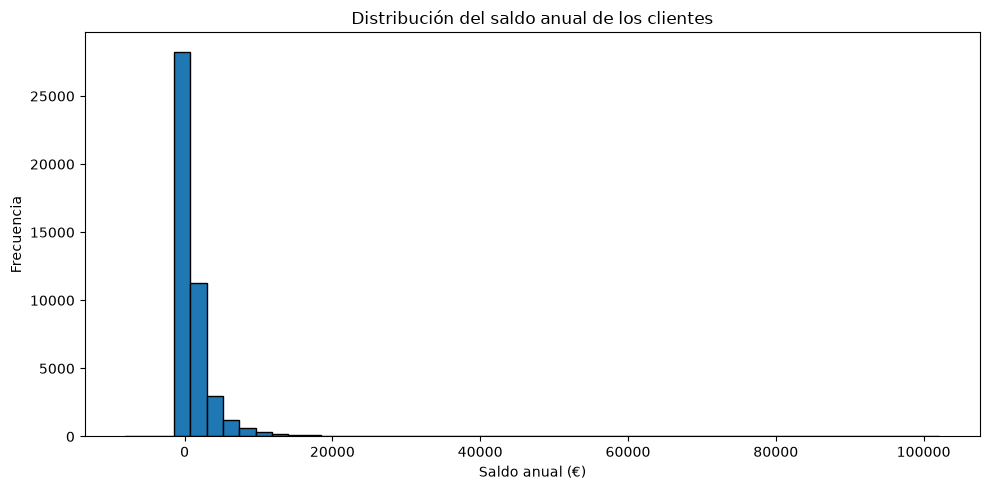

In [30]:
# Distribución del saldo anual

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['balance'], bins=50, edgecolor='black')
plt.title('Distribución del saldo anual de los clientes')
plt.xlabel('Saldo anual (€)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

## 22. Distribución del saldo anual

El histograma muestra una distribución asimétrica hacia la derecha. La mayor concentración de clientes se encuentra en saldos relativamente bajos, mientras que existen pocos registros con saldos considerablemente elevados.

**Hallazgo:** los valores extremos influyen en la media, por lo que la mediana representa mejor el saldo central de los clientes.

In [31]:
# Identificación de valores atípicos mediante IQR

Q1 = df['balance'].quantile(0.25)
Q3 = df['balance'].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")

Q1: 72.0
Q3: 1428.0
IQR: 1356.0
Límite inferior: -1962.0
Límite superior: 3462.0


## 23. Identificación de valores atípicos en el saldo

Se aplicó el método del rango intercuartílico (IQR) para establecer los límites de detección:

- Límite inferior: -1,962 €.
- Límite superior: 3,462 €.

**Hallazgo:** los saldos fuera de este intervalo se consideran posibles valores atípicos y requieren revisión antes de decidir su tratamiento.

In [32]:
# Cantidad y proporción de posibles valores atípicos

valores_atipicos = df[
    (df['balance'] < limite_inferior) |
    (df['balance'] > limite_superior)
]

cantidad_atipicos = len(valores_atipicos)
porcentaje_atipicos = cantidad_atipicos / len(df) * 100

print(f"Registros atípicos: {cantidad_atipicos:,}")
print(f"Porcentaje de la base: {porcentaje_atipicos:.2f}%")

Registros atípicos: 4,729
Porcentaje de la base: 10.46%


## 24. Proporción de valores atípicos

Se identificaron 4,729 registros fuera de los límites establecidos mediante el método IQR, equivalentes al 10.46% de la base.

**Hallazgo:** la proporción de posibles valores atípicos es relevante. Se conservarán inicialmente para evitar perder información financiera potencialmente válida.

In [34]:
# Clasificación de clientes según su saldo

df['grupo_balance'] = 'Dentro del rango'

df.loc[
    df['balance'] < limite_inferior,
    'grupo_balance'
] = 'Saldo bajo atípico'

df.loc[
    df['balance'] > limite_superior,
    'grupo_balance'
] = 'Saldo alto atípico'

# Conversión por grupo de saldo

conversion_balance = (
    df.groupby('grupo_balance')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_balance)

grupo_balance
Dentro del rango      11.17
Saldo alto atípico    16.26
Saldo bajo atípico     5.88
Name: y, dtype: float64


## 25. Conversión según clasificación del saldo

- Saldo alto atípico: 16.26%.
- Dentro del rango: 11.17%.
- Saldo bajo atípico: 5.88%.

**Hallazgo:** los clientes con saldos altos atípicos presentan la mayor tasa de conversión, mientras que aquellos con saldos bajos atípicos registran la menor.

In [35]:
# Conversión según crédito hipotecario

conversion_housing = (
    df.groupby('housing')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_housing)

housing
no     16.7
yes     7.7
Name: y, dtype: float64


## 26. Conversión según crédito hipotecario

- Sin crédito hipotecario: 16.70%.
- Con crédito hipotecario: 7.70%.

**Hallazgo:** los clientes sin crédito hipotecario presentan una mayor tasa de conversión.

In [36]:
# Conversión según préstamo personal

conversion_loan = (
    df.groupby('loan')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_loan)

loan
no     12.66
yes     6.68
Name: y, dtype: float64


## 27. Conversión según préstamo personal

- Sin préstamo personal: 12.66%.
- Con préstamo personal: 6.68%.

**Hallazgo:** los clientes sin préstamo personal presentan una mayor tasa de conversión.

In [37]:
# Conversión según número de contactos anteriores

conversion_previous = (
    df.groupby('previous')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_previous)

previous
0        9.16
1       21.03
2       21.65
3       25.74
4       23.95
5       26.36
6       29.96
7       26.34
8       30.23
9       26.09
10      38.81
11      23.08
12      22.73
13      23.68
14      26.32
15       5.00
16       0.00
17      20.00
18       0.00
19      18.18
20      12.50
21      25.00
22      16.67
23      12.50
24       0.00
25       0.00
26      50.00
27       0.00
28       0.00
29      25.00
30      33.33
32       0.00
35       0.00
37       0.00
38       0.00
40       0.00
41       0.00
51       0.00
55     100.00
58     100.00
275      0.00
Name: y, dtype: float64


## 28. Conversión según contactos anteriores

Los clientes sin contactos previos presentan una conversión de 9.16%. En varias categorías con contactos anteriores, la conversión supera el 20%.

**Hallazgo:** los antecedentes de contacto muestran una posible relación con la conversión. Los resultados de categorías con pocos registros requieren validación mediante el análisis de volúmenes.

In [38]:
# Volumen y conversión según contactos anteriores

volumen_previous = df.groupby('previous').agg(
    total_clientes=('y', 'count'),
    contrataciones=('y', lambda x: (x == 'yes').sum())
)

volumen_previous['conversion'] = (
    volumen_previous['contrataciones'] /
    volumen_previous['total_clientes'] * 100
).round(2)

volumen_previous.head(15)

,total_clientes,contrataciones,conversion
previous,,,
0,36954,3384,9.16
1,2772,583,21.03
2,2106,456,21.65
3,1142,294,25.74
4,714,171,23.95
5,459,121,26.36
6,277,83,29.96
7,205,54,26.34
8,129,39,30.23


## 29. Volumen y conversión según contactos anteriores

- 0 contactos: 36,954 clientes y 3,384 contrataciones.
- 1 contacto: 2,772 clientes y 583 contrataciones.
- 2 contactos: 2,106 clientes y 456 contrataciones.
- 3 contactos: 1,142 clientes y 294 contrataciones.

**Hallazgo:** los clientes con antecedentes de contacto presentan mayores tasas de conversión, aunque el grupo sin contactos previos concentra el mayor volumen de contrataciones.

In [39]:
# Duración promedio de llamadas según resultado comercial

duracion_conversion = df.groupby('y')['duration'].agg(
    ['count', 'mean', 'median']
).round(2)

duracion_conversion

,count,mean,median
y,,,
no,39922,221.18,164.0
yes,5289,537.29,426.0


## 30. Duración de llamadas según resultado comercial

- Sin contratación: duración media de 221.18 segundos y mediana de 164.
- Con contratación: duración media de 537.29 segundos y mediana de 426.

**Hallazgo:** las llamadas asociadas a contrataciones presentan mayor duración promedio y mediana.

In [40]:
# Agrupar llamadas por duración

df['grupo_duracion'] = pd.cut(
    df['duration'],
    bins=[-1, 60, 180, 300, 600, float('inf')],
    labels=['0-60', '61-180', '181-300', '301-600', 'Más de 600']
)

conversion_duracion = (
    df.groupby('grupo_duracion', observed=True)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_duracion)

grupo_duracion
0-60           0.19
61-180         3.91
181-300       10.92
301-600       19.15
Más de 600    48.36
Name: y, dtype: float64


## 31. Conversión por rango de duración de llamadas

- 0-60 segundos: 0.19%.
- 61-180 segundos: 3.91%.
- 181-300 segundos: 10.92%.
- 301-600 segundos: 19.15%.
- Más de 600 segundos: 48.36%.

**Hallazgo:** la conversión aumenta conforme a la duración de las llamadas.

**Consideración:** esta variable no debe utilizarse para predecir la contratación antes del contacto, debido a que se conoce al finalizar la llamada.

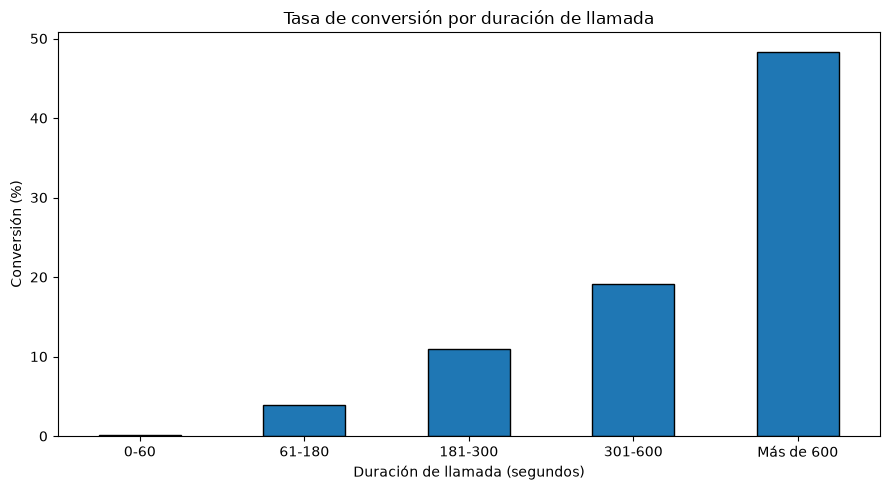

In [41]:
# Conversión por duración de llamadas

conversion_duracion.plot(
    kind='bar',
    figsize=(9, 5),
    edgecolor='black'
)

plt.title('Tasa de conversión por duración de llamada')
plt.xlabel('Duración de llamada (segundos)')
plt.ylabel('Conversión (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 32. Visualización de conversión por duración de llamada

La gráfica muestra una tendencia creciente en la tasa de conversión conforme aumenta la duración de las llamadas.

**Hallazgo:** las llamadas de más de 600 segundos presentan una conversión de 48.36%, frente al 0.19% de las llamadas de hasta 60 segundos.

**Consideración:** la duración es una variable posterior al contacto y no debe utilizarse para modelos de predicción previos a la campaña.

In [42]:
# Matriz de correlación de variables numéricas

correlacion = df.select_dtypes(include='number').corr()

correlacion.round(2)

,age,balance,day_of_week,duration,campaign,pdays,previous
age,1.00,0.10,-0.01,-0.00,0.00,-0.02,0.00
balance,0.10,1.00,0.00,0.02,-0.01,0.00,0.02
day_of_week,-0.01,0.00,1.00,-0.03,0.16,-0.09,-0.05
duration,-0.00,0.02,-0.03,1.00,-0.08,-0.00,0.00
campaign,0.00,-0.01,0.16,-0.08,1.00,-0.09,-0.03
pdays,-0.02,0.00,-0.09,-0.00,-0.09,1.00,0.45
previous,0.00,0.02,-0.05,0.00,-0.03,0.45,1.00


## 33. Matriz de correlación

La matriz muestra correlaciones lineales generalmente débiles entre las variables numéricas.

La relación más destacada se encuentra entre `pdays` y `previous`, con un coeficiente de 0.45.

**Hallazgo:** no se identifican relaciones lineales fuertes entre las variables numéricas. Esta evaluación no permite descartar relaciones no lineales o asociaciones con variables categóricas.

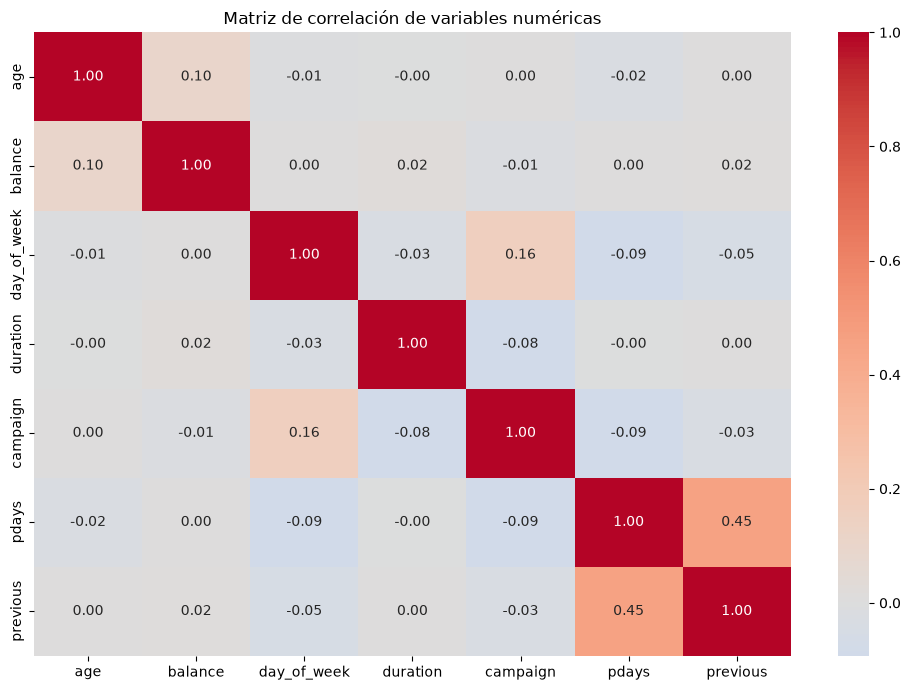

In [43]:
# Visualización de la matriz de correlación

import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Matriz de correlación de variables numéricas')
plt.tight_layout()
plt.show()

In [44]:
# Matriz de correlación completa

correlacion = df.select_dtypes(include='number').corr()

print(correlacion.round(3).to_string())

               age  balance  day_of_week  duration  campaign  pdays  previous
age          1.000    0.098       -0.009    -0.005     0.005 -0.024     0.001
balance      0.098    1.000        0.005     0.022    -0.015  0.003     0.017
day_of_week -0.009    0.005        1.000    -0.030     0.162 -0.093    -0.052
duration    -0.005    0.022       -0.030     1.000    -0.085 -0.002     0.001
campaign     0.005   -0.015        0.162    -0.085     1.000 -0.089    -0.033
pdays       -0.024    0.003       -0.093    -0.002    -0.089  1.000     0.455
previous     0.001    0.017       -0.052     0.001    -0.033  0.455     1.000


## 33. Matriz de correlación

La matriz presenta correlaciones lineales predominantemente débiles.

Las relaciones más relevantes son:

- `pdays` y `previous`: 0.455.
- `day_of_week` y `campaign`: 0.162.
- `age` y `balance`: 0.098.
- `duration` y `campaign`: -0.085.

**Hallazgo:** no se identifican correlaciones lineales fuertes entre las variables numéricas. La asociación entre `pdays` y `previous` es la más relevante.

In [45]:
# Conversión según incumplimiento crediticio

conversion_default = (
    df.groupby('default')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .round(2)
)

print(conversion_default)

default
no     11.80
yes     6.38
Name: y, dtype: float64


## 34. Conversión según incumplimiento crediticio

- Sin incumplimiento: 11.80%.
- Con incumplimiento: 6.38%.

**Hallazgo:** los clientes sin incumplimiento crediticio presentan una mayor tasa de conversión.

In [46]:
# Revisión de valores faltantes

faltantes = pd.DataFrame({
    'Valores_faltantes': df.isnull().sum(),
    'Porcentaje': (df.isnull().mean() * 100).round(2)
})

faltantes[faltantes['Valores_faltantes'] > 0].sort_values(
    by='Porcentaje',
    ascending=False
)

,Valores_faltantes,Porcentaje
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


## 35. Análisis de valores faltantes

Se identificaron valores faltantes en cuatro variables:

- `poutcome`: 36,959 (81.75%).
- `contact`: 13,020 (28.80%).
- `education`: 1,857 (4.11%).
- `job`: 288 (0.64%).

**Hallazgo:** `poutcome` concentra la mayor proporción de valores faltantes. Se conservarán inicialmente como una categoría independiente para evitar perder información.

In [47]:
# Relación entre antecedentes de campañas y valores faltantes

df['poutcome'].isnull().groupby(df['previous'] == 0).agg(
    ['count', 'sum']
)

,count,sum
previous,,
False,8257,5
True,36954,36954


- Los valores faltantes de `poutcome` están asociados con la ausencia de contactos en campañas anteriores (`previous = 0`). Por tanto, representan principalmente la falta de historial previo y no necesariamente errores de captura.

In [48]:
# Identificar registros con previous > 0 y poutcome faltante
casos_atipicos = df[
    (df['previous'] > 0) &
    (df['poutcome'].isnull())
]

casos_atipicos

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y,grupo_edad,grupo_balance,grupo_duracion
40658,61,retired,married,tertiary,no,3140,yes,yes,cellular,6,aug,975,4,98,1,NaN,yes,56-65,Dentro del rango,Más de 600
41821,39,management,married,tertiary,no,184,no,no,cellular,15,oct,206,1,168,5,NaN,no,36-45,Dentro del rango,181-300
42042,26,admin.,single,secondary,no,338,no,no,cellular,29,oct,209,1,188,2,NaN,yes,26-35,Dentro del rango,181-300
43978,30,technician,single,secondary,no,254,yes,yes,cellular,24,jun,167,3,416,2,NaN,no,26-35,Dentro del rango,61-180
45021,37,management,married,secondary,no,209,no,no,cellular,14,oct,183,3,528,7,NaN,no,36-45,Dentro del rango,181-300


- Se identificaron 5 registros con antecedentes de contacto (`previous > 0` y `pdays > 0`), pero sin información sobre el resultado de la campaña anterior (`poutcome`). Se conservarán como valores faltantes para evitar imputaciones sin fundamento.

In [49]:
# Revisar valores faltantes de contact según el canal registrado
df['contact'].isnull().groupby(df['poutcome'].isnull()).agg(
    ['count', 'sum']
)

,count,sum
poutcome,,
False,8252,70
True,36959,12950


- La ausencia de `contact` es considerablemente mayor entre los registros sin historial de campañas anteriores (35.04%) que entre aquellos con historial registrado (0.85%). Se conservarán los valores faltantes para evaluar su tratamiento posteriormente.

In [50]:
# Relación entre contact faltante y contratación
df['contact'].isnull().groupby(df['y']).agg(
    ['count', 'sum']
)

,count,sum
y,,
no,39922,12490
yes,5289,530


- Los valores faltantes de `contact` representan el 31.28% de los clientes que no contrataron y el 10.02% de quienes sí contrataron. Su ausencia está asociada con el resultado comercial, por lo que no deben eliminarse automáticamente.

In [51]:
# Comparar conversión según disponibilidad de contact
conversion_contact = df.groupby(
    df['contact'].isnull()
)['y'].agg(
    clientes='count',
    contrataciones=lambda x: (x == 'yes').sum(),
    conversion=lambda x: (x == 'yes').mean() * 100
)

conversion_contact.round(2)

,clientes,contrataciones,conversion
contact,,,
False,32191,4759,14.78
True,13020,530,4.07


- Los registros sin información de `contact` presentan una conversión del 4.07%, frente al 14.78% de aquellos con canal identificado. Se conservarán como una categoría diferenciada para evitar perder información relevante y sesgar los resultados.

In [52]:
# Relación entre education faltante y contratación
df['education'].isnull().groupby(df['y']).agg(
    ['count', 'sum']
)

,count,sum
y,,
no,39922,1605
yes,5289,252


- Los valores faltantes de `education` representan el 4.02% de los clientes que no contrataron y el 4.76% de quienes sí contrataron. La diferencia es reducida; se conservarán para definir posteriormente una estrategia de tratamiento.

In [53]:
# Relación entre job faltante y contratación
df['job'].isnull().groupby(df['y']).agg(
    ['count', 'sum']
)

,count,sum
y,,
no,39922,254
yes,5289,34


- Los valores faltantes de `job` representan el 0.64% tanto de los clientes que no contrataron como de quienes sí contrataron. No se observa una diferencia relevante entre ambos grupos.

### Tratamiento de valores faltantes

- `poutcome`: conservar los faltantes como categoría "Sin historial previo", considerando que están asociados principalmente con `previous = 0`.
- `contact`: conservar los faltantes como categoría "No registrado", debido a su relación con la conversión comercial.
- `education`: conservar temporalmente como "Desconocido"; evaluar su impacto antes de imputar.
- `job`: conservar temporalmente como "Desconocido"; su proporción de faltantes es reducida (0.64%).

El DataFrame original se mantendrá sin modificaciones. El tratamiento se aplicará posteriormente sobre una copia.

In [54]:
# Crear copia para el procesamiento de datos
df_procesado = df.copy()

print("Copia de trabajo creada correctamente")
print(df_procesado.shape)

Copia de trabajo creada correctamente
(45211, 20)


In [55]:
# Identificar ausencia de historial en campañas anteriores
df_procesado['poutcome'] = df_procesado['poutcome'].fillna('sin_historial')

# Verificar resultado
df_procesado['poutcome'].value_counts()

poutcome
sin_historial    36959
failure           4901
other             1840
success           1511
Name: count, dtype: int64

In [56]:
# Identificar registros sin información del canal de contacto
df_procesado['contact'] = df_procesado['contact'].fillna('no_registrado')

# Verificar resultado
df_procesado['contact'].value_counts()

contact
cellular         29285
no_registrado    13020
telephone         2906
Name: count, dtype: int64

In [57]:
# Identificar nivel educativo no registrado
df_procesado['education'] = df_procesado['education'].fillna('desconocido')

# Verificar resultado
df_procesado['education'].value_counts()

education
secondary      23202
tertiary       13301
primary         6851
desconocido     1857
Name: count, dtype: int64

In [58]:
# Identificar ocupación no registrada
df_procesado['job'] = df_procesado['job'].fillna('desconocido')

# Verificar resultado
df_procesado['job'].value_counts()

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
desconocido       288
Name: count, dtype: int64

In [59]:
# Verificar valores faltantes después del tratamiento
df_procesado[
    ['poutcome', 'contact', 'education', 'job']
].isnull().sum()


poutcome     0
contact      0
education    0
job          0
dtype: int64

In [60]:
# Validar dimensiones después del procesamiento
print("Dimensiones originales:", df.shape)
print("Dimensiones procesadas:", df_procesado.shape)

Dimensiones originales: (45211, 20)
Dimensiones procesadas: (45211, 20)


### Resultado de la limpieza de datos

- Se trataron los valores faltantes de `poutcome`, `contact`, `education` y `job` mediante categorías explícitas.
- Se conservaron los 45,211 registros originales.
- Las cuatro variables presentan cero valores nulos.
- El DataFrame original permanece sin modificaciones.

In [62]:
# Identificar registros duplicados
duplicados = df_procesado.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 0


- No se identificaron registros duplicados en el conjunto de datos procesado. Se conservan las 45,211 observaciones.

In [63]:
# Revisar tipos de datos
df_procesado.dtypes

age                  int64
job                    str
marital                str
education              str
default                str
balance              int64
housing                str
loan                   str
contact                str
day_of_week          int64
month                  str
duration             int64
campaign             int64
pdays                int64
previous             int64
poutcome               str
y                      str
grupo_edad        category
grupo_balance          str
grupo_duracion    category
dtype: object

In [64]:
# Crear versión limpia sin variables auxiliares de análisis
df_limpio = df_procesado.drop(
    columns=['grupo_edad', 'grupo_balance', 'grupo_duracion']
)

print("Dimensiones:", df_limpio.shape)
print("Valores faltantes:", df_limpio.isnull().sum().sum())


Dimensiones: (45211, 17)
Valores faltantes: 0


In [75]:
# Exportar dataset limpio al repositorio
ruta_salida = r'C:\Users\Carlo\OneDrive\Documentos\Github\banking-commercial-intelligence-main\banking-commercial-intelligence-main\datos\procesados\bank_marketing_limpio.csv'

df_limpio.to_csv(
    ruta_salida,
    index=False,
    encoding='utf-8'
)

print("Dataset exportado correctamente")

Dataset exportado correctamente
